In [1]:
# Core PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Data, metrics, plotting
import os, glob, zipfile, shutil, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_recall_fscore_support, roc_curve, auc)
from sklearn.preprocessing import label_binarize

# Reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("⚠️  No GPU found. In Colab: Runtime → Change runtime type → T4 GPU, then run again.")

# Folder where every figure / table / model is saved
RESULTS_DIR = "/content/results" if os.path.exists("/content") else "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

Using device: cuda


In [2]:
ZIP_NAME    = "Orange Fruit Image Dataset for Classification.zip"   # change this if your file has a different name
EXTRACT_DIR = "/content/orange_data" if os.path.exists("/content") else "orange_data"
IMG_EXT     = (".jpg", ".jpeg", ".png", ".bmp")

def find_zip():
    # 1) already in the Colab working folder?
    for p in [f"/content/{ZIP_NAME}", ZIP_NAME]:
        if os.path.exists(p):
            return p
    # 2) on Google Drive?
    try:
        from google.colab import drive
        if not os.path.exists("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        hits = glob.glob(f"/content/drive/MyDrive/**/{ZIP_NAME}", recursive=True)
        if not hits:
            hits = (glob.glob("/content/drive/MyDrive/**/*Orange*.zip", recursive=True) +
                    glob.glob("/content/drive/MyDrive/**/*orange*.zip", recursive=True))
        if hits:
            return hits[0]
    except Exception as e:
        print("Google Drive not used:", e)
    # 3) ask for a direct upload
    try:
        from google.colab import files
        print(f"Zip not found on Drive. Please upload {ZIP_NAME} ...")
        uploaded = files.upload()
        name = list(uploaded.keys())[0]
        return os.path.abspath(name)
    except Exception as e:
        raise FileNotFoundError(f"Could not find or upload {ZIP_NAME}: {e}")

def extract_all(zip_path, out_dir):
    print("Extracting", zip_path, "...")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out_dir)
    # Some datasets have zips inside the zip: extract those too
    for _ in range(3):
        inner = [p for p in glob.glob(os.path.join(out_dir, "**", "*.zip"), recursive=True)]
        if not inner:
            break
        for p in inner:
            with zipfile.ZipFile(p) as z:
                z.extractall(os.path.splitext(p)[0])
            os.remove(p)

already = os.path.exists(EXTRACT_DIR) and any(
    f.lower().endswith(IMG_EXT) for _, _, fs in os.walk(EXTRACT_DIR) for f in fs)
if already:
    print("Dataset already extracted at", EXTRACT_DIR)
else:
    zip_path = find_zip()
    print("Using zip:", zip_path)
    extract_all(zip_path, EXTRACT_DIR)

# macOS-made zips contain a hidden "__MACOSX" folder full of "._xxx.jpg" metadata files.
# They are NOT images (opening them raises UnidentifiedImageError), so delete them.
for junk in glob.glob(os.path.join(EXTRACT_DIR, "**", "__MACOSX"), recursive=True):
    shutil.rmtree(junk, ignore_errors=True)
    print("Removed macOS junk folder:", junk)
print("Done.")

Mounted at /content/drive
Using zip: /content/drive/MyDrive/Orange Fruit Image Dataset for Classification.zip
Extracting /content/drive/MyDrive/Orange Fruit Image Dataset for Classification.zip ...
Done.


In [3]:
def find_dataset_roots(base):
    # Return {root_folder: {class_name: [image paths]}} for every folder with >= 3 image sub-folders
    roots = {}
    for current, subdirs, _ in os.walk(base):
        subdirs[:] = [d for d in subdirs if d != "__MACOSX" and not d.startswith(".")]   # skip macOS junk
        classes = {}
        for d in sorted(subdirs):
            imgs = [os.path.join(current, d, f) for f in os.listdir(os.path.join(current, d))
                    if f.lower().endswith(IMG_EXT) and not f.startswith(".")]   # "._xxx.jpg" are not images
            if imgs:
                classes[d] = sorted(imgs)
        if len(classes) >= 3:
            roots[current] = classes
    return roots

roots = find_dataset_roots(EXTRACT_DIR)
if not roots:
    raise RuntimeError("No class folders found. Print os.walk(EXTRACT_DIR) to inspect the zip layout.")

print("Image sets found:\n")
for r, cls in roots.items():
    total = sum(len(v) for v in cls.values())
    print(f"📁 {os.path.relpath(r, EXTRACT_DIR)}  ->  {total} images")
    for c, v in cls.items():
        print(f"     {c:<25s} {len(v)}")
    print()

# If several image sets were found, prefer original images over any augmented copies.
def score(r):
    name = os.path.basename(r).lower()
    preferred = any(k in name for k in ["main", "orig", "primary", "raw"])
    avoided   = "aug" in name or "agu" in name      # the dataset spells it "Agumented"
    return (not preferred, avoided, sum(len(v) for v in roots[r].values()))

DATA_ROOT = sorted(roots, key=score)[0]
# DATA_ROOT = "/content/orange_data/...."   # ← uncomment to force a specific folder
class_to_files = roots[DATA_ROOT]
class_names = list(class_to_files.keys())
NUM_CLASSES = len(class_names)
print("✅ Using:", DATA_ROOT)
print("Classes:", class_names)
total_selected = sum(len(v) for v in class_to_files.values())
print("Images per class:", {c: len(v) for c, v in class_to_files.items()}, "| total:", total_selected)
assert "aug" not in os.path.basename(DATA_ROOT).lower() and "agu" not in os.path.basename(DATA_ROOT).lower(), \
    "Picked an augmented folder. Set DATA_ROOT to the folder with the original images manually."
if total_selected != 15000:
    print("⚠️  Expected 15,000 images (3,000 per class). Check that DATA_ROOT is the 'dataset' folder.")

Image sets found:

📁 Orange Fruit Image Dataset for Classification/OrangeClassificationDataset/dataset  ->  15000 images
     blackspotted_orange       3000
     cankered_orange           3000
     fresh_orange              3000
     green_orange              3000
     rotten_orange             3000

✅ Using: /content/orange_data/Orange Fruit Image Dataset for Classification/OrangeClassificationDataset/dataset
Classes: ['blackspotted_orange', 'cankered_orange', 'fresh_orange', 'green_orange', 'rotten_orange']
Images per class: {'blackspotted_orange': 3000, 'cankered_orange': 3000, 'fresh_orange': 3000, 'green_orange': 3000, 'rotten_orange': 3000} | total: 15000


### Check for duplicate images (prevents data leakage)

In [4]:
import hashlib
def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

t0 = time.time()
hash_classes = {}                       # hash -> set of classes it appears in
file_hash = {}
for c, files_ in class_to_files.items():
    for p in files_:
        h = md5(p); file_hash[p] = h
        hash_classes.setdefault(h, set()).add(c)

conflicting = {h for h, cs in hash_classes.items() if len(cs) > 1}
seen, removed_dup, removed_conflict = set(), 0, 0
for c in class_names:
    kept = []
    for p in class_to_files[c]:
        h = file_hash[p]
        if h in conflicting:
            removed_conflict += 1; continue
        if (c, h) in seen:
            removed_dup += 1; continue
        seen.add((c, h)); kept.append(p)
    class_to_files[c] = kept

print(f"Hashed {len(file_hash)} files in {time.time()-t0:.1f}s")
print(f"Exact duplicates removed (same class)      : {removed_dup}")
print(f"Images removed (same photo in 2+ classes)  : {removed_conflict}")
print("Images per class now:", {c: len(v) for c, v in class_to_files.items()},
      "| total:", sum(len(v) for v in class_to_files.values()))

Hashed 15000 files in 0.5s
Exact duplicates removed (same class)      : 0
Images removed (same photo in 2+ classes)  : 0
Images per class now: {'blackspotted_orange': 3000, 'cankered_orange': 3000, 'fresh_orange': 3000, 'green_orange': 3000, 'rotten_orange': 3000} | total: 15000


## 3. Explore the data


Total images: 15000


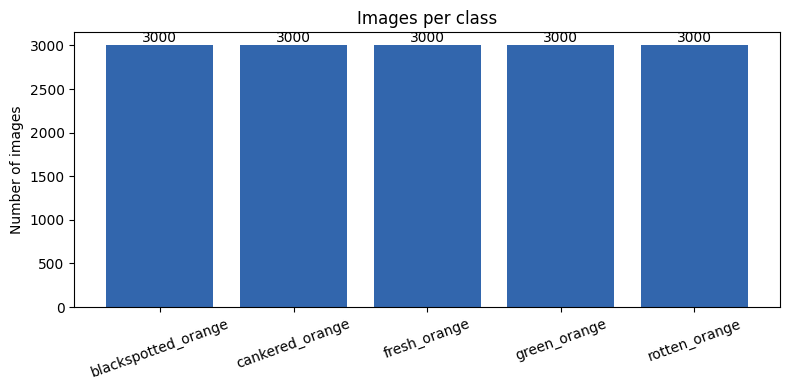

Example original sizes (W x H): [(224, 224)]


In [5]:
counts = {c: len(v) for c, v in class_to_files.items()}
total_images = sum(counts.values())
print("Total images:", total_images)

plt.figure(figsize=(8, 4))
bars = plt.bar(counts.keys(), counts.values(), color="#3266ad")
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height(), str(int(b.get_height())),
             ha="center", va="bottom", fontsize=10)
plt.title("Images per class")
plt.ylabel("Number of images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/class_distribution.png", dpi=150)
plt.show()

# Original image sizes (check a few per class)
sizes = []
for v in class_to_files.values():
    for p in v[:5]:
        try:
            sizes.append(Image.open(p).size)
        except Exception as e:
            print("Unreadable file skipped:", p)
print("Example original sizes (W x H):", sorted(set(sizes))[:5])

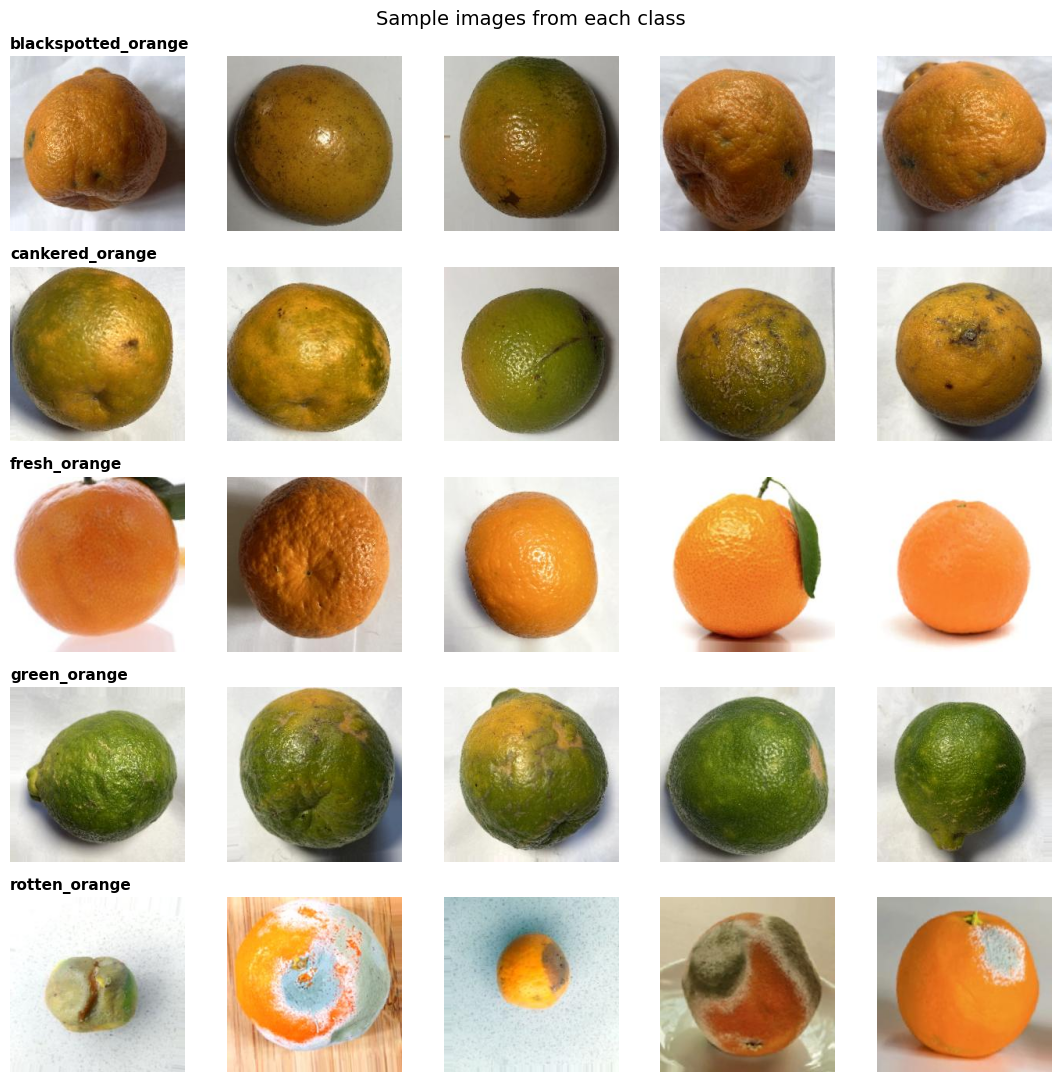

In [6]:
# A grid of sample images: 5 per class
n_per_class = 5
fig, axes = plt.subplots(NUM_CLASSES, n_per_class, figsize=(n_per_class*2.2, NUM_CLASSES*2.2))
for i, c in enumerate(class_names):
    for j, p in enumerate(random.sample(class_to_files[c], n_per_class)):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.suptitle("Sample images from each class", fontsize=14)
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/sample_images.png", dpi=150)
plt.show()

## 4. Train / validation / test split


In [7]:
all_paths  = [p for c in class_names for p in class_to_files[c]]
all_labels = [i for i, c in enumerate(class_names) for _ in class_to_files[c]]

train_p, temp_p, train_y, temp_y = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED)
val_p, test_p, val_y, test_y = train_test_split(
    temp_p, temp_y, test_size=0.50, stratify=temp_y, random_state=SEED)

split_table = pd.DataFrame({
    "Train": pd.Series(train_y).value_counts().sort_index().values,
    "Validation": pd.Series(val_y).value_counts().sort_index().values,
    "Test": pd.Series(test_y).value_counts().sort_index().values,
}, index=class_names)
split_table.loc["Total"] = split_table.sum()
print(split_table)

                     Train  Validation  Test
blackspotted_orange   2100         450   450
cankered_orange       2100         450   450
fresh_orange          2100         450   450
green_orange          2100         450   450
rotten_orange         2100         450   450
Total                10500        2250  2250


### Load the images into memory

In [8]:
IMG_SIZE   = 128
BATCH_SIZE = 32

def load_images(paths, labels):
    imgs, ys = [], []
    for p, y in zip(paths, labels):
        try:
            img = Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
            imgs.append(img); ys.append(y)
        except Exception as e:
            print("Skipping unreadable file:", p, e)
    return imgs, ys

t0 = time.time()
train_imgs, train_y = load_images(train_p, train_y)
val_imgs,   val_y   = load_images(val_p,   val_y)
test_imgs,  test_y  = load_images(test_p,  test_y)
print(f"Loaded {len(train_imgs)} train / {len(val_imgs)} val / {len(test_imgs)} test images "
      f"in {time.time()-t0:.1f}s")

class FruitDataset(Dataset):
    # Holds pre-loaded PIL images + labels and applies a transform on the fly
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        return self.transform(self.images[idx]), self.labels[idx]

Loaded 10500 train / 2250 val / 2250 test images in 15.7s


## 5. Round 1: basic transform only (no augmentation)

The minimal transform just turns each image into a tensor with values in `[0, 1]` and shape `[3, 128, 128]`. No flipping, rotating or colour changes yet.

Batch shape: (32, 3, 128, 128)


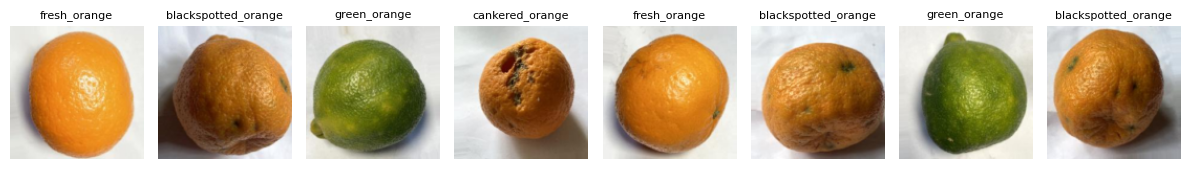

In [9]:
basic_transform = transforms.Compose([
    transforms.ToTensor(),             # PIL (already 128x128) -> tensor in [0, 1]
])

train_ds_plain = FruitDataset(train_imgs, train_y, basic_transform)
val_ds         = FruitDataset(val_imgs,   val_y,   basic_transform)
test_ds        = FruitDataset(test_imgs,  test_y,  basic_transform)

train_loader_plain = DataLoader(train_ds_plain, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader         = DataLoader(val_ds,         batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader        = DataLoader(test_ds,        batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# One batch as a sanity check
images, labels = next(iter(train_loader_plain))
print("Batch shape:", tuple(images.shape))
plt.figure(figsize=(12, 3))
for i in range(8):
    plt.subplot(1, 8, i+1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(class_names[labels[i]], fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()

In [10]:
def conv_block(in_ch, out_ch, batchnorm=False):
    layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
    if batchnorm:
        layers.append(nn.BatchNorm2d(out_ch))
    layers += [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
    return nn.Sequential(*layers)

class CNN_Basic(nn.Module):
    # 3 conv blocks, no BatchNorm, no Dropout
    def __init__(self, num_classes=5, img_size=128):
        super().__init__()
        self.features = nn.Sequential(        # each block = Conv -> ReLU -> MaxPool
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
        )
        with torch.no_grad():
            n_flat = self.features(torch.zeros(1, 3, img_size, img_size)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_flat, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

class CNN_Improved(nn.Module):
    # 4 conv blocks with BatchNorm + Dropout in the head
    def __init__(self, num_classes=5, img_size=128, p_dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(        # each block = Conv -> BatchNorm -> ReLU -> MaxPool
            conv_block(3, 32, batchnorm=True),
            conv_block(32, 64, batchnorm=True),
            conv_block(64, 128, batchnorm=True),
            conv_block(128, 256, batchnorm=True),
        )
        with torch.no_grad():
            n_flat = self.features(torch.zeros(1, 3, img_size, img_size)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(n_flat, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p_dropout),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model_basic = CNN_Basic(NUM_CLASSES, IMG_SIZE).to(device)
print(model_basic)
print(f"\nTrainable parameters: {count_params(model_basic):,}")

CNN_Basic(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=256, out_features=5, bias=True)
  )
)

Trainable parameters: 8,483,397


In [11]:
# Layer-by-layer summary (output shapes + parameters)
try:
    from torchsummary import summary
except ImportError:
    !pip install -q torchsummary
    from torchsummary import summary
summary(model_basic, input_size=(3, IMG_SIZE, IMG_SIZE), device=device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
              ReLU-2         [-1, 32, 128, 128]               0
         MaxPool2d-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 64, 64, 64]          18,496
              ReLU-5           [-1, 64, 64, 64]               0
         MaxPool2d-6           [-1, 64, 32, 32]               0
            Conv2d-7          [-1, 128, 32, 32]          73,856
              ReLU-8          [-1, 128, 32, 32]               0
         MaxPool2d-9          [-1, 128, 16, 16]               0
          Flatten-10                [-1, 32768]               0
           Linear-11                  [-1, 256]       8,388,864
             ReLU-12                  [-1, 256]               0
           Linear-13                    [-1, 5]           1,285
Total params: 8,483,397
Trainable param

## 7. Training loop

In [12]:
def run_epoch(model, loader, criterion, optimizer=None):
    # Trains if an optimizer is given, otherwise evaluates. Returns (loss, accuracy).
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * imgs.size(0)
            correct    += (outputs.argmax(1) == labels).sum().item()
            total      += labels.size(0)
    return total_loss / total, correct / total

def train_model(model, train_loader, val_loader, epochs=20, lr=1e-3, weight_decay=0.0,
                scheduler_type=None, save_path="best_model.pth"):
    # scheduler_type: None (constant LR) or "cosine" (LR decays smoothly from lr to lr/100)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=lr/100)
                 if scheduler_type == "cosine" else None)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "lr": []}
    best_val_acc, best_epoch = 0.0, 0
    start = time.time()

    for epoch in range(1, epochs + 1):
        lr_now = optimizer.param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler:
            scheduler.step()

        for k, v in zip(history.keys(), [tr_loss, va_loss, tr_acc, va_acc, lr_now]):
            history[k].append(v)

        flag = ""
        if va_acc > best_val_acc:
            best_val_acc, best_epoch = va_acc, epoch
            torch.save(model.state_dict(), save_path)
            flag = "  ✓ best"
        print(f"Epoch {epoch:2d}/{epochs} | lr {lr_now:.1e} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f}{flag}")

    history["train_time_s"] = time.time() - start
    history["best_epoch"], history["best_val_acc"] = best_epoch, best_val_acc
    print(f"\nTraining time: {history['train_time_s']/60:.1f} min | "
          f"best val acc {best_val_acc:.4f} at epoch {best_epoch}")
    model.load_state_dict(torch.load(save_path, map_location=device))   # restore the best weights
    return history

In [13]:
# Plot helper for loss / accuracy curves
BLUE, ORANGE, GRAY = "#3266ad", "#e07b39", "#88877f"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.5})

def plot_history(h, title, fname):
    ep = np.arange(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    ax1.plot(ep, h["train_acc"], "o-", color=BLUE, ms=4, label="Train")
    ax1.plot(ep, h["val_acc"],   "o-", color=ORANGE, ms=4, label="Validation")
    ax1.axvline(h["best_epoch"], color=GRAY, ls=":", label=f"Best epoch ({h['best_epoch']})")
    ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
    ax1.set_title("Accuracy (higher = better)"); ax1.set_xlabel("Epoch"); ax1.legend()

    ax2.plot(ep, h["train_loss"], "o-", color=BLUE, ms=4, label="Train")
    ax2.plot(ep, h["val_loss"],   "o-", color=ORANGE, ms=4, label="Validation")
    ax2.axvline(h["best_epoch"], color=GRAY, ls=":")
    ax2.set_title("Loss (lower = better)"); ax2.set_xlabel("Epoch"); ax2.legend()
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

### Train Round 1 (basic CNN, no augmentation)


Epoch  1/20 | lr 1.0e-03 | train loss 0.4698 acc 0.8174 | val loss 0.2649 acc 0.9151  ✓ best
Epoch  2/20 | lr 1.0e-03 | train loss 0.1484 acc 0.9486 | val loss 0.1305 acc 0.9596  ✓ best
Epoch  3/20 | lr 1.0e-03 | train loss 0.0901 acc 0.9689 | val loss 0.1292 acc 0.9524
Epoch  4/20 | lr 1.0e-03 | train loss 0.0505 acc 0.9812 | val loss 0.0401 acc 0.9836  ✓ best
Epoch  5/20 | lr 1.0e-03 | train loss 0.0435 acc 0.9847 | val loss 0.1130 acc 0.9640
Epoch  6/20 | lr 1.0e-03 | train loss 0.0309 acc 0.9884 | val loss 0.0657 acc 0.9782
Epoch  7/20 | lr 1.0e-03 | train loss 0.0383 acc 0.9861 | val loss 0.0462 acc 0.9827
Epoch  8/20 | lr 1.0e-03 | train loss 0.0339 acc 0.9884 | val loss 0.0744 acc 0.9773
Epoch  9/20 | lr 1.0e-03 | train loss 0.0284 acc 0.9893 | val loss 0.0444 acc 0.9818
Epoch 10/20 | lr 1.0e-03 | train loss 0.0304 acc 0.9907 | val loss 0.0365 acc 0.9884  ✓ best
Epoch 11/20 | lr 1.0e-03 | train loss 0.0102 acc 0.9963 | val loss 0.0569 acc 0.9800
Epoch 12/20 | lr 1.0e-03 | train 

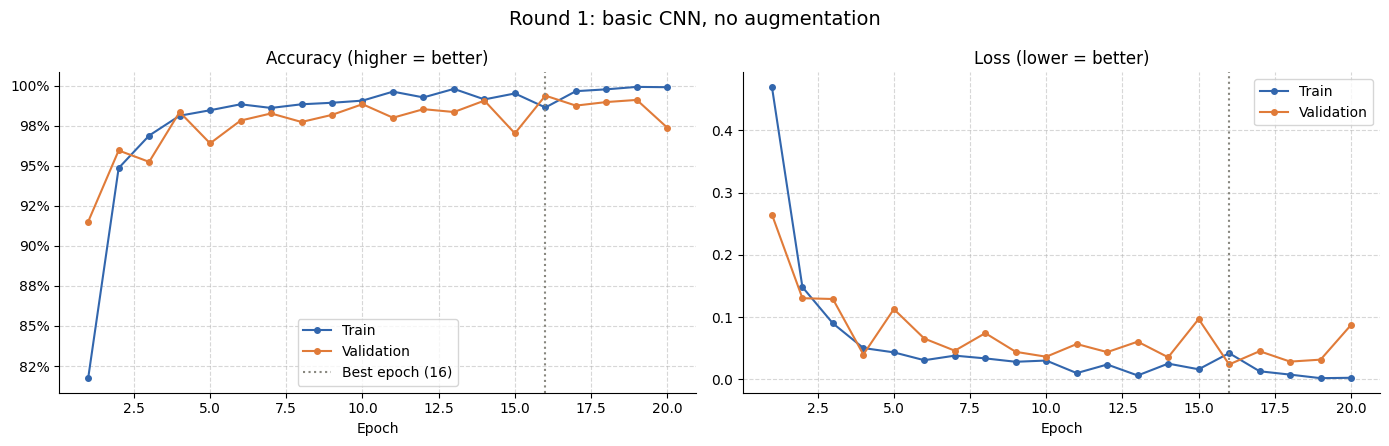

In [14]:
EPOCHS_R1 = 20
history_basic = train_model(model_basic, train_loader_plain, val_loader,
                            epochs=EPOCHS_R1, lr=1e-3,
                            save_path=f"{RESULTS_DIR}/cnn_basic_best.pth")
plot_history(history_basic, "Round 1: basic CNN, no augmentation", "curves_round1.png")

Sample image class: blackspotted_orange


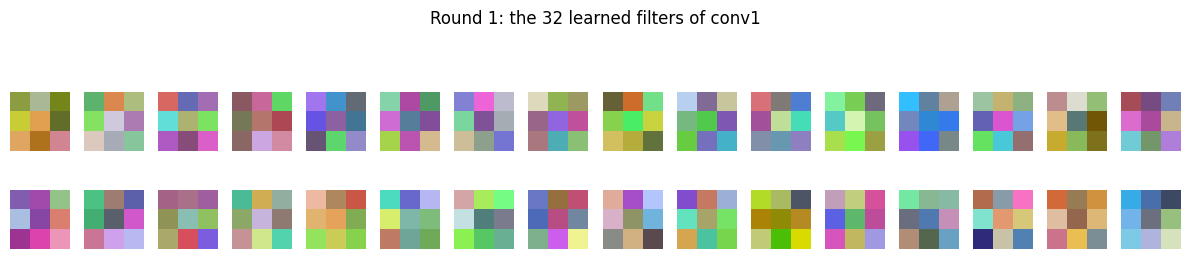

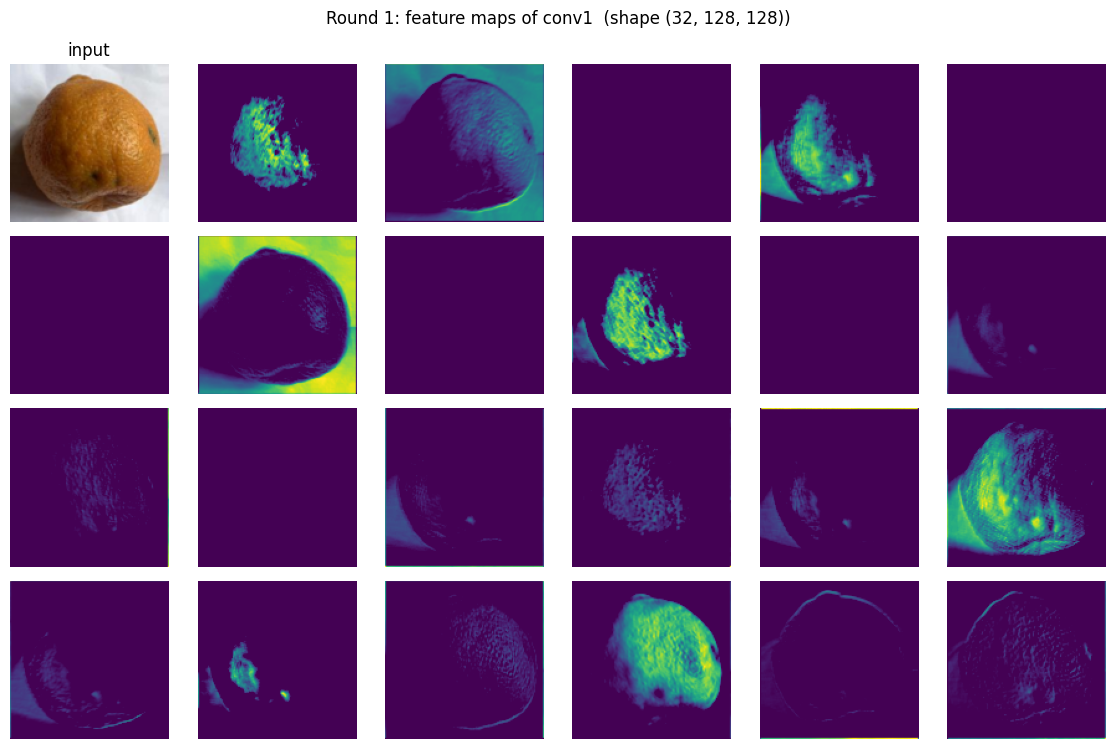

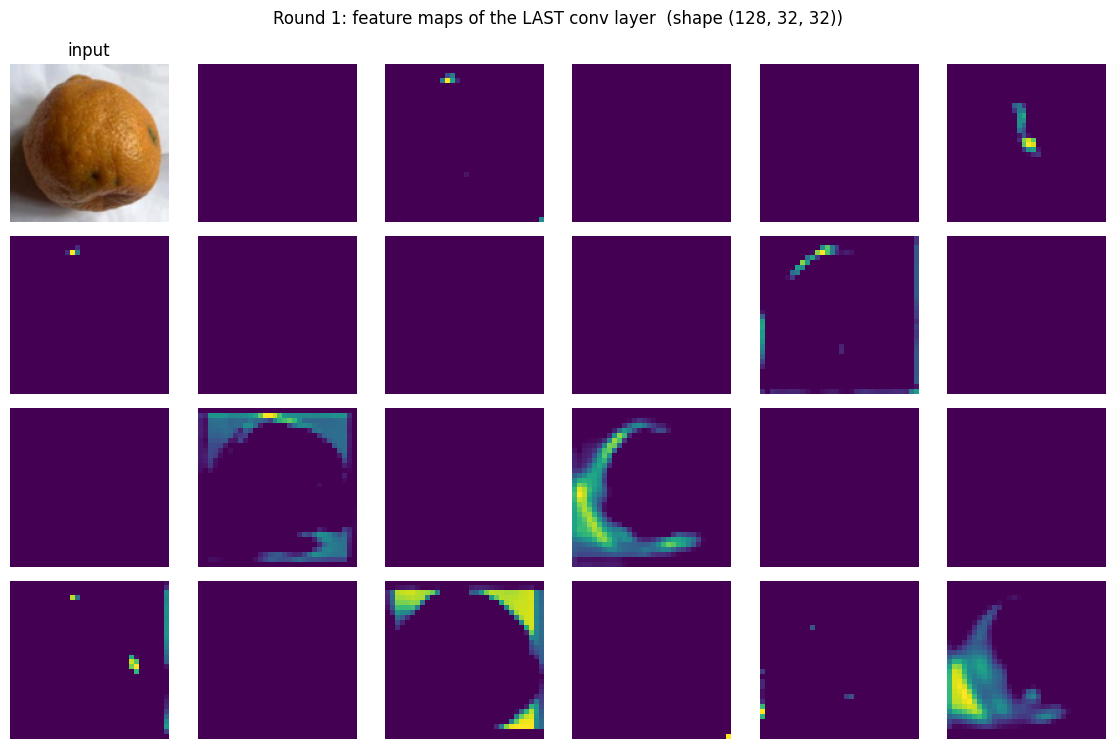

In [15]:
def show_filters(model, title, fname):
    w = model.features[0][0].weight.data.clone().cpu()          # [32, 3, 3, 3]
    w = (w - w.min()) / (w.max() - w.min() + 1e-8)
    n = w.shape[0]
    plt.figure(figsize=(12, 3))
    for i in range(n):
        plt.subplot(2, n // 2, i + 1)
        plt.imshow(w[i].permute(1, 2, 0)); plt.axis("off")
    plt.suptitle(title); plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{fname}", dpi=150); plt.show()

def show_feature_maps(model, img, title, fname, layer="first", n_maps=23):
    model.eval()
    x = img.unsqueeze(0).to(device)
    with torch.no_grad():
        if layer == "first":
            maps = F.relu(model.features[0][0](x))           # conv1 output, before pooling
        else:
            blocks = list(model.features)
            for b in blocks[:-1]:
                x = b(x)
            maps = blocks[-1][:-1](x)                        # last block, before pooling
    maps = maps.cpu()[0]
    cols = 6; rows = int(np.ceil((n_maps + 1) / cols))
    plt.figure(figsize=(cols*1.9, rows*1.9))
    plt.subplot(rows, cols, 1); plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
    for i in range(min(n_maps, maps.shape[0])):
        plt.subplot(rows, cols, i + 2); plt.imshow(maps[i], cmap="viridis"); plt.axis("off")
    plt.suptitle(f"{title}  (shape {tuple(maps.shape)})"); plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{fname}", dpi=150); plt.show()

# pick one defective validation orange (black-spotted if available) for the visualizations
sample_idx = next((i for i, y in enumerate(val_y) if "black" in class_names[y].lower()), 0)
sample_img, sample_label = val_ds[sample_idx]
print("Sample image class:", class_names[sample_label])

show_filters(model_basic, "Round 1: the 32 learned filters of conv1", "filters_round1.png")
show_feature_maps(model_basic, sample_img, "Round 1: feature maps of conv1", "fmaps_first_round1.png", "first")
show_feature_maps(model_basic, sample_img, "Round 1: feature maps of the LAST conv layer", "fmaps_last_round1.png", "last")

## 9. Round 2: fix overfitting with augmentation, BatchNorm and dropout

1. **Data augmentation (training set only).** Every time a training image is used, it gets a random flip, rotation, crop/zoom and brightness/contrast change. Oranges are photographed at any angle, distance and light, so this teaches the model to handle that variety and stops it memorizing exact pictures. Validation and test images stay **unchanged**, so we measure performance on normal images. We deliberately use **no hue shift** and only a small saturation change: colour is exactly what separates a *green* orange from a *fresh* one, so changing it would teach the model wrong labels.
2. **BatchNorm** after every conv layer stabilizes and speeds up training.
3. **Dropout (0.5)** randomly switches off half of the neurons in the classification head during training, so the network can't rely on a few features.
4. **Weight decay** (L2), a lower starting learning rate (`5e-4`) and a **cosine learning-rate schedule** that lowers the learning rate smoothly to `5e-6` by the last epoch. A smaller, decaying step size keeps BatchNorm's running statistics stable, so validation results don't jump around between epochs.
5. **More epochs (30).** Augmented data is harder to fit, so the regularized model needs longer to converge than the basic one.

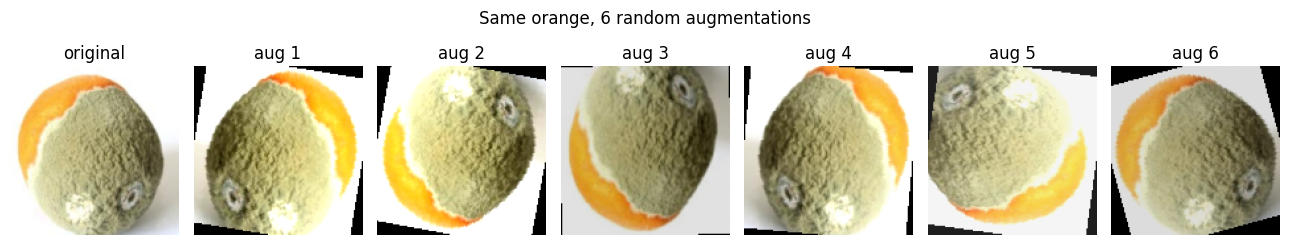

In [16]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),    # random zoom / crop
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),                             # a round fruit has no fixed "up"
    transforms.RandomRotation(20),
    # Only mild colour changes and NO hue shift: colour is what separates green from fresh (orange) oranges
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
])

train_ds_aug     = FruitDataset(train_imgs, train_y, train_transform)
train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

# The SAME image, augmented 6 different ways
plt.figure(figsize=(13, 2.6))
plt.subplot(1, 7, 1); plt.imshow(train_imgs[0]); plt.title("original"); plt.axis("off")
for i in range(6):
    plt.subplot(1, 7, i + 2); plt.imshow(train_ds_aug[0][0].permute(1, 2, 0)); plt.title(f"aug {i+1}"); plt.axis("off")
plt.suptitle("Same orange, 6 random augmentations"); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/augmentation_examples.png", dpi=150); plt.show()

In [17]:
model_improved = CNN_Improved(NUM_CLASSES, IMG_SIZE, p_dropout=0.5).to(device)
print(f"Trainable parameters: {count_params(model_improved):,}")
summary(model_improved, input_size=(3, IMG_SIZE, IMG_SIZE), device=device.type)

Trainable parameters: 4,585,221
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
       BatchNorm2d-2         [-1, 32, 128, 128]              64
              ReLU-3         [-1, 32, 128, 128]               0
         MaxPool2d-4           [-1, 32, 64, 64]               0
            Conv2d-5           [-1, 64, 64, 64]          18,496
       BatchNorm2d-6           [-1, 64, 64, 64]             128
              ReLU-7           [-1, 64, 64, 64]               0
         MaxPool2d-8           [-1, 64, 32, 32]               0
            Conv2d-9          [-1, 128, 32, 32]          73,856
      BatchNorm2d-10          [-1, 128, 32, 32]             256
             ReLU-11          [-1, 128, 32, 32]               0
        MaxPool2d-12          [-1, 128, 16, 16]               0
           Conv2d-13          [-1, 256, 16, 16]         295,168
      B

### Train Round 2
30 epochs, about 12 to 15 minutes on a T4 GPU (augmentation runs on the CPU for 10,500 images per epoch).

Epoch  1/30 | lr 5.0e-04 | train loss 0.7717 acc 0.7160 | val loss 0.4385 acc 0.8267  ✓ best
Epoch  2/30 | lr 5.0e-04 | train loss 0.4852 acc 0.8223 | val loss 0.3194 acc 0.8929  ✓ best
Epoch  3/30 | lr 4.9e-04 | train loss 0.3497 acc 0.8712 | val loss 0.3914 acc 0.8613
Epoch  4/30 | lr 4.9e-04 | train loss 0.2916 acc 0.8932 | val loss 2.2381 acc 0.6431
Epoch  5/30 | lr 4.8e-04 | train loss 0.2773 acc 0.8970 | val loss 0.3387 acc 0.8547
Epoch  6/30 | lr 4.7e-04 | train loss 0.2368 acc 0.9090 | val loss 0.1255 acc 0.9471  ✓ best
Epoch  7/30 | lr 4.5e-04 | train loss 0.2195 acc 0.9156 | val loss 0.3758 acc 0.9013
Epoch  8/30 | lr 4.4e-04 | train loss 0.1974 acc 0.9260 | val loss 0.1118 acc 0.9524  ✓ best
Epoch  9/30 | lr 4.2e-04 | train loss 0.1939 acc 0.9223 | val loss 0.1002 acc 0.9600  ✓ best
Epoch 10/30 | lr 4.0e-04 | train loss 0.1781 acc 0.9330 | val loss 0.0834 acc 0.9644  ✓ best
Epoch 11/30 | lr 3.8e-04 | train loss 0.1611 acc 0.9348 | val loss 0.1106 acc 0.9587
Epoch 12/30 | lr 

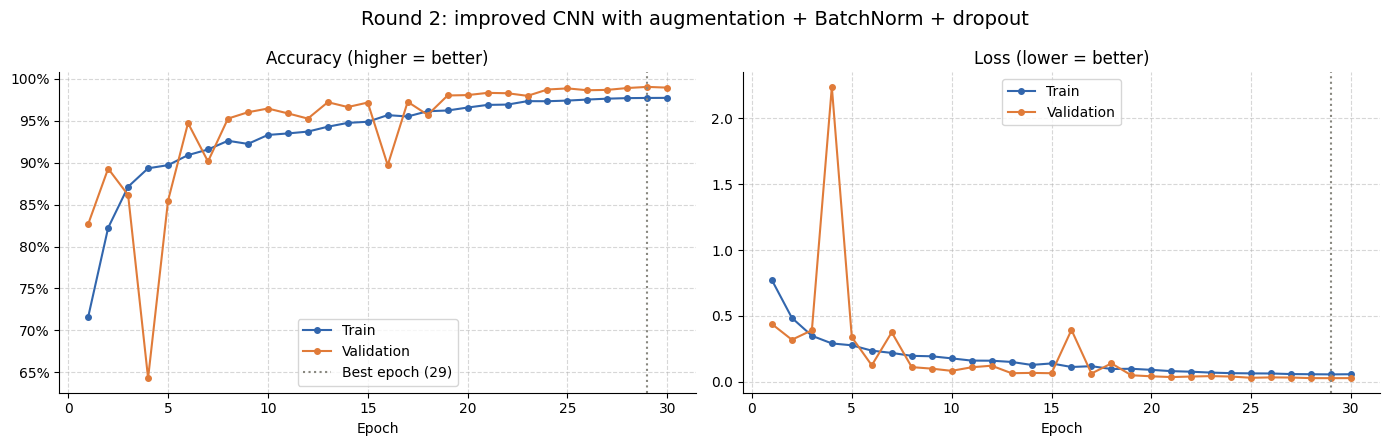

In [18]:
EPOCHS_R2 = 30
history_improved = train_model(model_improved, train_loader_aug, val_loader,
                               epochs=EPOCHS_R2, lr=5e-4, weight_decay=1e-4, scheduler_type="cosine",
                               save_path=f"{RESULTS_DIR}/cnn_improved_best.pth")
plot_history(history_improved, "Round 2: improved CNN with augmentation + BatchNorm + dropout",
             "curves_round2.png")

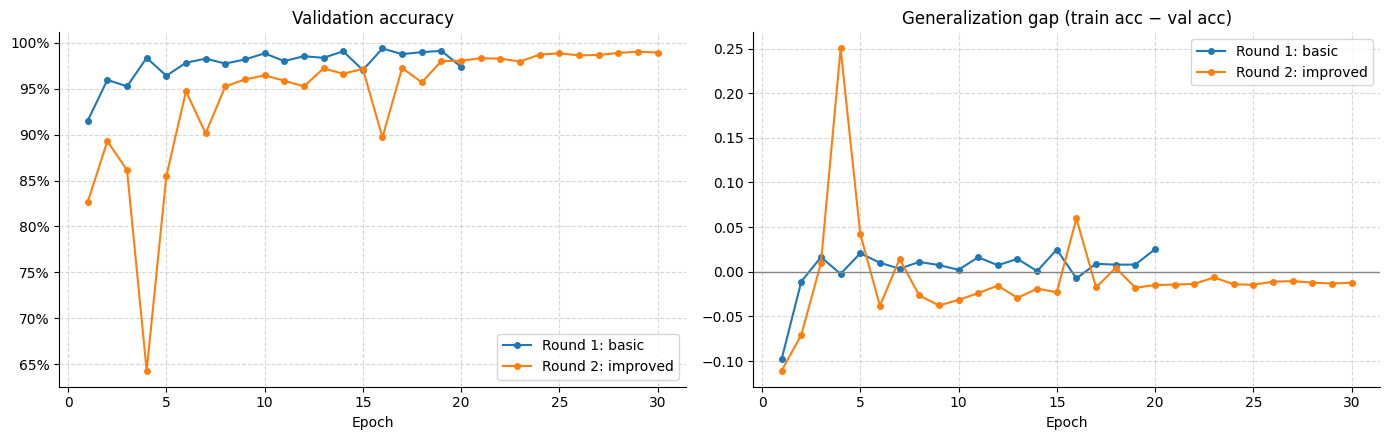

Best val acc Round 1: 0.9938  (epoch 16)
Best val acc Round 2: 0.9902  (epoch 29)
Final-epoch gap Round 1: 0.0253 | Round 2: -0.0122


In [19]:
# Compare the two rounds side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(np.arange(1, len(history_basic["val_acc"])+1), history_basic["val_acc"], "o-", ms=4, label="Round 1: basic")
ax1.plot(np.arange(1, len(history_improved["val_acc"])+1), history_improved["val_acc"], "o-", ms=4, label="Round 2: improved")
ax1.set_title("Validation accuracy"); ax1.set_xlabel("Epoch"); ax1.legend()
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))

gap1 = np.array(history_basic["train_acc"]) - np.array(history_basic["val_acc"])
gap2 = np.array(history_improved["train_acc"]) - np.array(history_improved["val_acc"])
ax2.plot(np.arange(1, len(gap1)+1), gap1, "o-", ms=4, label="Round 1: basic")
ax2.plot(np.arange(1, len(gap2)+1), gap2, "o-", ms=4, label="Round 2: improved")
ax2.axhline(0, color=GRAY, lw=1)
ax2.set_title("Generalization gap (train acc − val acc)"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/round_comparison.png", dpi=150); plt.show()

print(f"Best val acc Round 1: {history_basic['best_val_acc']:.4f}  (epoch {history_basic['best_epoch']})")
print(f"Best val acc Round 2: {history_improved['best_val_acc']:.4f}  (epoch {history_improved['best_epoch']})")
print(f"Final-epoch gap Round 1: {gap1[-1]:.4f} | Round 2: {gap2[-1]:.4f}")

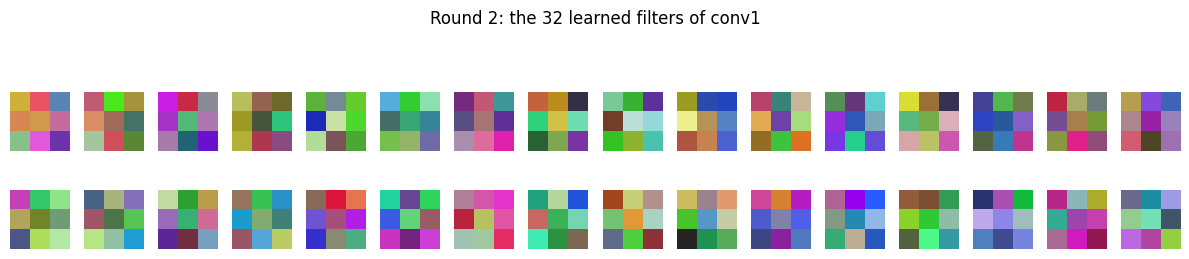

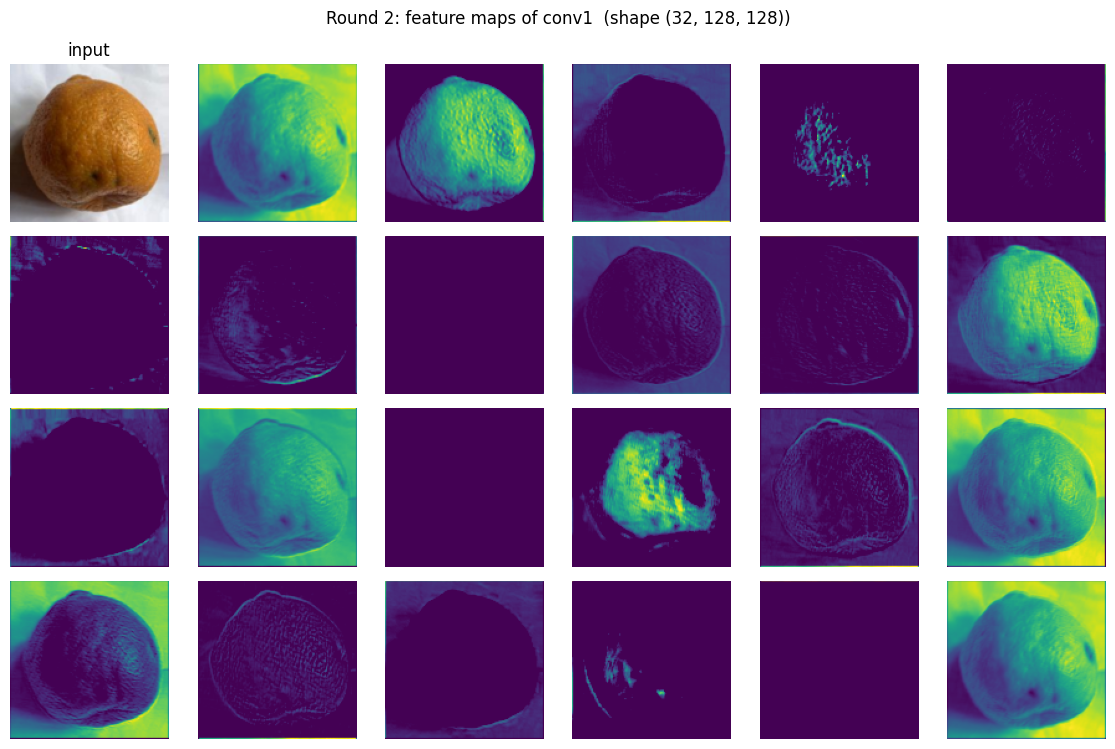

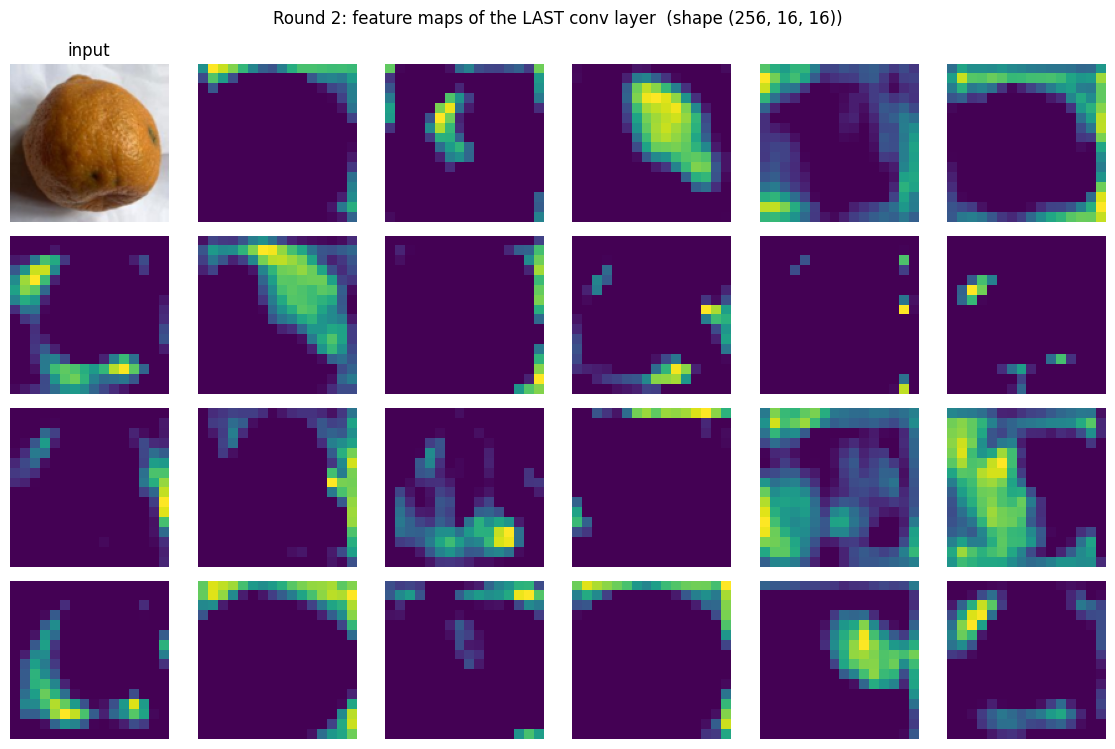

In [20]:
show_filters(model_improved, "Round 2: the 32 learned filters of conv1", "filters_round2.png")
show_feature_maps(model_improved, sample_img, "Round 2: feature maps of conv1", "fmaps_first_round2.png", "first")
show_feature_maps(model_improved, sample_img, "Round 2: feature maps of the LAST conv layer", "fmaps_last_round2.png", "last")

## 10. Final evaluation on the test set

The test set was never used for training or for choosing the best epoch, so this is the honest measure of how well each model works on new oranges. Both models are evaluated with their best saved weights.

In [21]:
def get_predictions(model, loader):
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            probs.append(F.softmax(model(imgs.to(device)), dim=1).cpu())
            targets.append(labels)
    probs = torch.cat(probs).numpy()
    return probs.argmax(1), torch.cat(targets).numpy(), probs

def summarize(name, model, history, y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"Model": name,
            "Parameters": f"{count_params(model):,}",
            "Best epoch": history["best_epoch"],
            "Train time (min)": round(history["train_time_s"]/60, 2),
            "Best val acc": round(history["best_val_acc"], 4),
            "Test accuracy": round(accuracy_score(y_true, y_pred), 4),
            "Macro precision": round(p, 4),
            "Macro recall": round(r, 4),
            "Macro F1": round(f1, 4)}

pred_b, true_b, prob_b = get_predictions(model_basic, test_loader)
pred_i, true_i, prob_i = get_predictions(model_improved, test_loader)

results = pd.DataFrame([summarize("Round 1: CNN_Basic", model_basic, history_basic, true_b, pred_b),
                        summarize("Round 2: CNN_Improved", model_improved, history_improved, true_i, pred_i)])
results.to_csv(f"{RESULTS_DIR}/results_comparison.csv", index=False)
results

,Model,Parameters,Best epoch,Train time (min),Best val acc,Test accuracy,Macro precision,Macro recall,Macro F1
0,Round 1: CNN_Basic,"8,483,397",16,2.92,0.9938,0.9933,0.9934,0.9933,0.9933
1,Round 2: CNN_Improved,"4,585,221",29,10.94,0.9902,0.9911,0.9912,0.9911,0.9911


From here on we analyze the **final model (Round 2)** in detail: `y_true`, `y_pred` and `y_prob` hold its test-set results. To analyze the Round 1 model instead, change the next cell to use `pred_b, true_b, prob_b` and `model_basic`.

In [22]:
final_model = model_improved
y_pred, y_true, y_prob = pred_i, true_i, prob_i
print(f"Final test accuracy: {accuracy_score(y_true, y_pred)*100:.2f}%  "
      f"({(y_pred == y_true).sum()}/{len(y_true)} test images correct)")

Final test accuracy: 99.11%  (2230/2250 test images correct)


### Confusion matrix

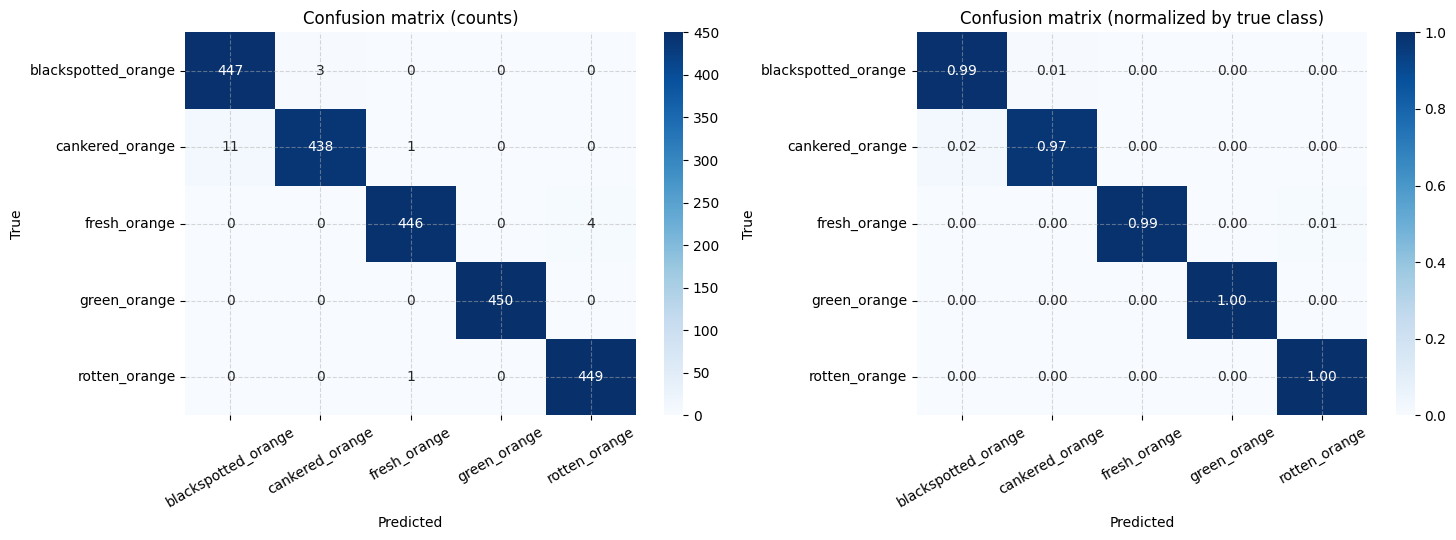

In [23]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("Confusion matrix (normalized by true class)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/confusion_matrix.png", dpi=150); plt.show()

### Classification report (precision, recall, F1)

- **Precision:** of all oranges *predicted* as class X, how many really were X (few false alarms).
- **Recall:** of all oranges that *really are* class X, how many the model found (few misses).
- **F1-score:** the balance (harmonic mean) of precision and recall.
- **Support:** number of test images in that class.

In [24]:
report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
print(report)
pd.DataFrame(classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
             ).transpose().to_csv(f"{RESULTS_DIR}/classification_report.csv")

                     precision    recall  f1-score   support

blackspotted_orange     0.9760    0.9933    0.9846       450
    cankered_orange     0.9932    0.9733    0.9832       450
       fresh_orange     0.9955    0.9911    0.9933       450
       green_orange     1.0000    1.0000    1.0000       450
      rotten_orange     0.9912    0.9978    0.9945       450

           accuracy                         0.9911      2250
          macro avg     0.9912    0.9911    0.9911      2250
       weighted avg     0.9912    0.9911    0.9911      2250



### Per-class accuracy, best and worst classes

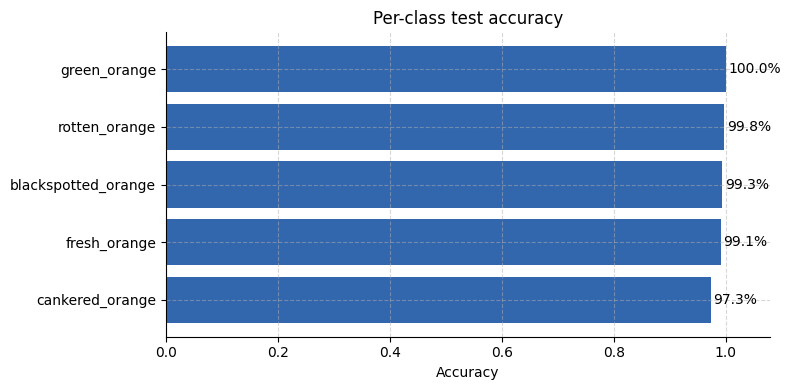

Best class : green_orange (100.00%)
Worst class: cankered_orange (97.33%)

Most common mistakes (true → predicted):
  cankered_orange → blackspotted_orange: 11 images
  fresh_orange → rotten_orange: 4 images
  blackspotted_orange → cankered_orange: 3 images
  rotten_orange → fresh_orange: 1 images
  cankered_orange → fresh_orange: 1 images


In [25]:
per_class_acc = cm.diagonal() / cm.sum(axis=1)
order = np.argsort(per_class_acc)

plt.figure(figsize=(8, 4))
bars = plt.barh([class_names[i] for i in order], per_class_acc[order], color=BLUE)
for b, v in zip(bars, per_class_acc[order]):
    plt.text(v + 0.005, b.get_y() + b.get_height()/2, f"{v*100:.1f}%", va="center")
plt.xlim(0, 1.08); plt.xlabel("Accuracy"); plt.title("Per-class test accuracy")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/per_class_accuracy.png", dpi=150); plt.show()

print(f"Best class : {class_names[order[-1]]} ({per_class_acc[order[-1]]*100:.2f}%)")
print(f"Worst class: {class_names[order[0]]} ({per_class_acc[order[0]]*100:.2f}%)")

# Most frequent confusions
off = [(cm[i, j], class_names[i], class_names[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
print("\nMost common mistakes (true → predicted):")
for n, t, p in sorted(off, reverse=True)[:5]:
    print(f"  {t} → {p}: {n} images")

### ROC curves (one-vs-rest)

For each class, the ROC curve shows the trade-off between catching that disease (true positive rate) and false alarms (false positive rate) as the decision threshold changes. 

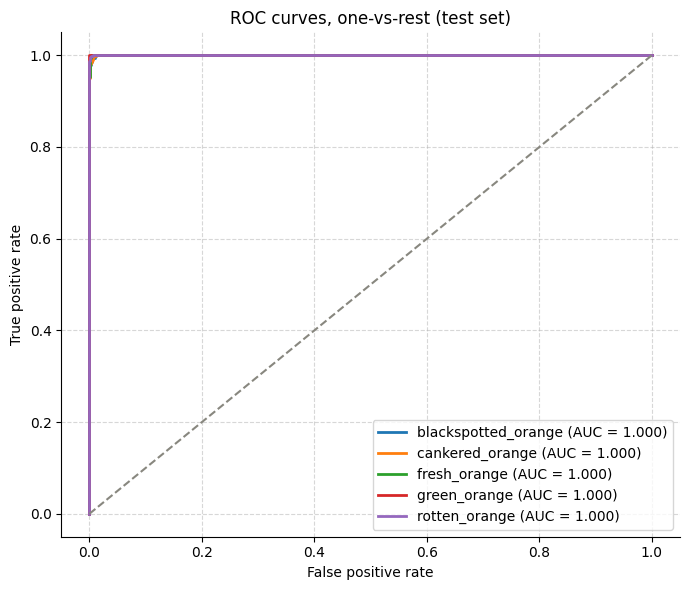

In [26]:
y_true_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
plt.figure(figsize=(7, 6))
for i, c in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "--", color=GRAY)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves, one-vs-rest (test set)"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/roc_curves.png", dpi=150); plt.show()

### Sample predictions

Random test images with the predicted class and the model's confidence. Green title = correct, red = wrong.

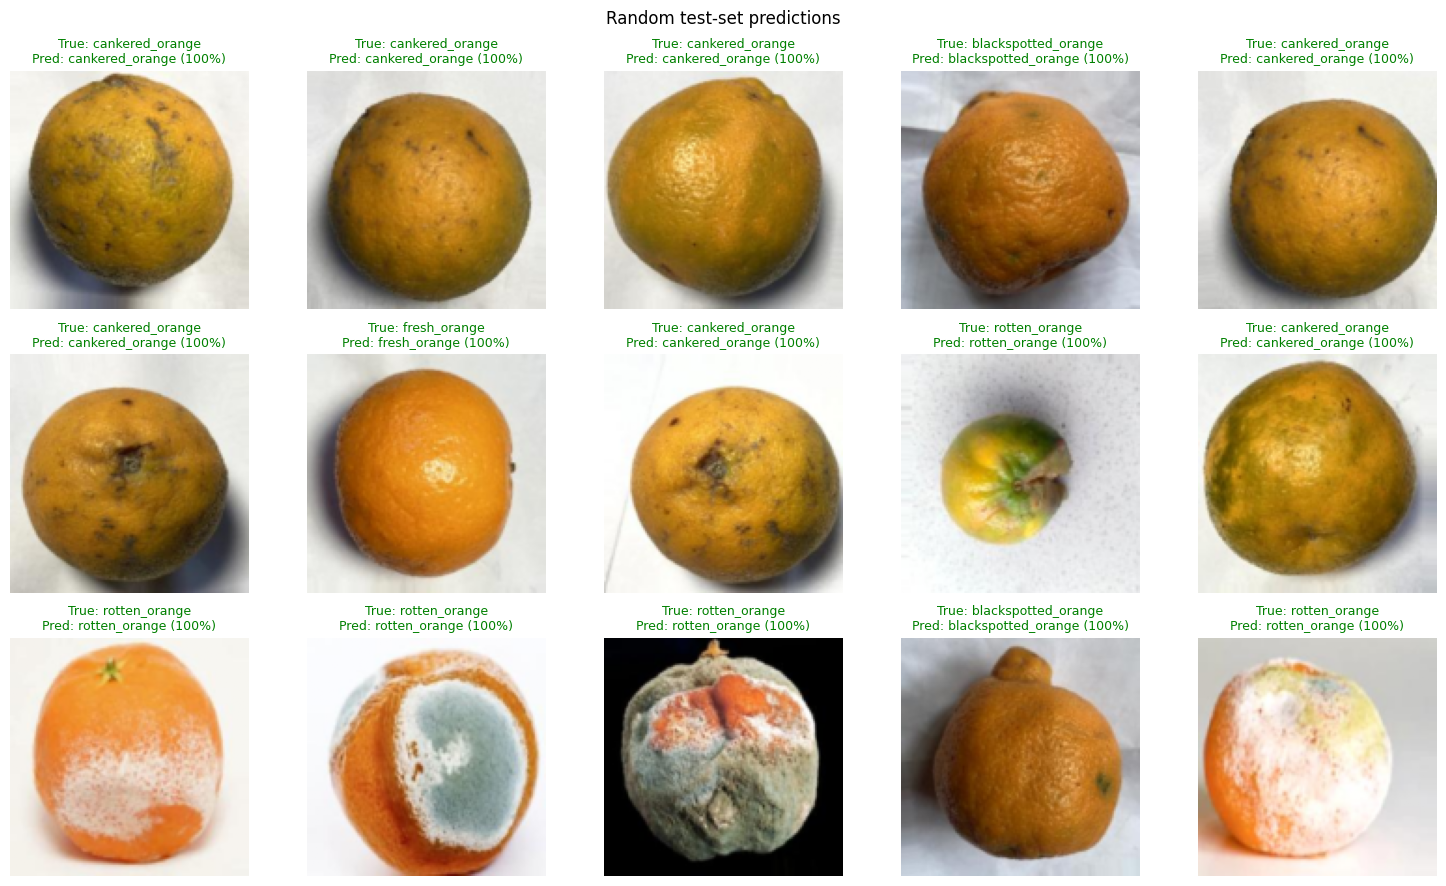

In [27]:
idxs = random.sample(range(len(test_ds)), 15)
plt.figure(figsize=(15, 9))
for k, idx in enumerate(idxs):
    img, label = test_ds[idx]
    pred, conf = y_pred[idx], y_prob[idx].max()
    plt.subplot(3, 5, k + 1)
    plt.imshow(img.permute(1, 2, 0))
    plt.title(f"True: {class_names[label]}\nPred: {class_names[pred]} ({conf*100:.0f}%)",
              fontsize=9, color="green" if pred == label else "red")
    plt.axis("off")
plt.suptitle("Random test-set predictions"); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/sample_predictions.png", dpi=150); plt.show()

### Misclassified images

Total misclassified test images: 20 / 2250


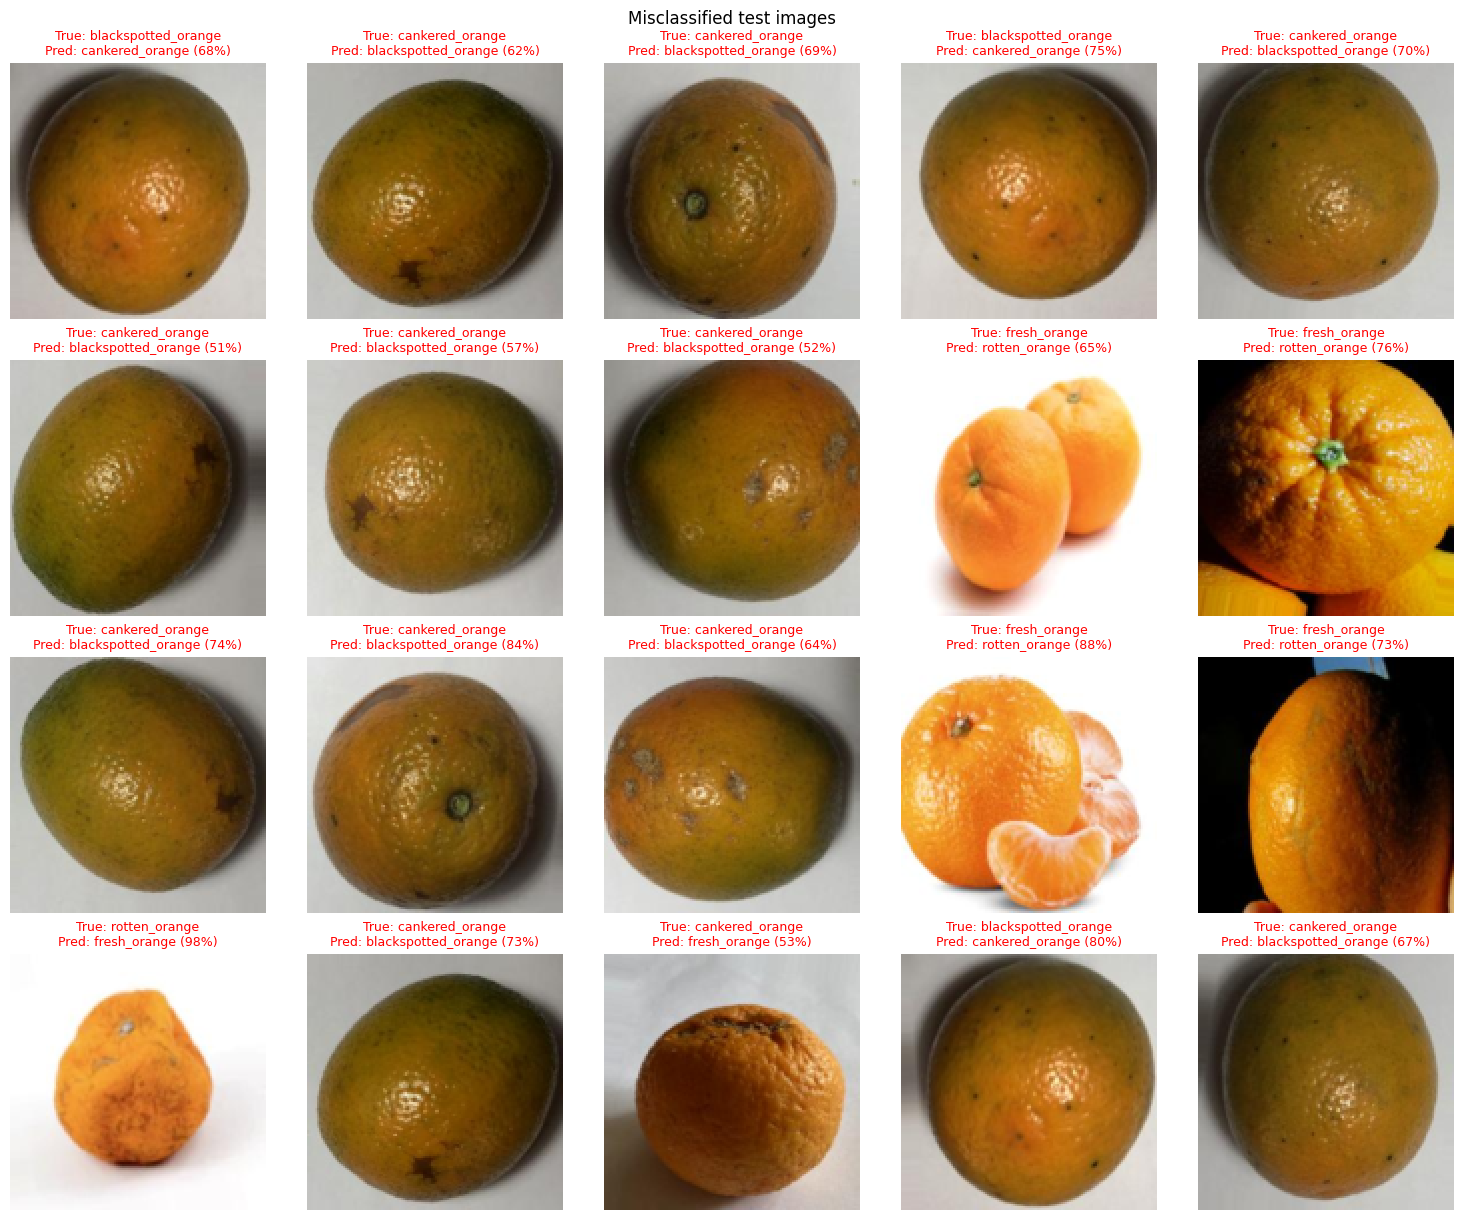

In [28]:
wrong = np.where(y_pred != y_true)[0]
print(f"Total misclassified test images: {len(wrong)} / {len(y_true)}")

n_show = min(20, len(wrong))
if n_show:
    cols = 5; rows = int(np.ceil(n_show / cols))
    plt.figure(figsize=(cols*3, rows*3.1))
    for k, idx in enumerate(wrong[:n_show]):
        img, label = test_ds[idx]
        plt.subplot(rows, cols, k + 1)
        plt.imshow(img.permute(1, 2, 0))
        plt.title(f"True: {class_names[label]}\nPred: {class_names[y_pred[idx]]} ({y_prob[idx].max()*100:.0f}%)",
                  fontsize=9, color="red")
        plt.axis("off")
    plt.suptitle("Misclassified test images"); plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/misclassified.png", dpi=150); plt.show()

## 11. Results summary

In [29]:
rb, ri = results.iloc[0], results.iloc[1]
g1 = history_basic["train_acc"][-1] - history_basic["val_acc"][-1]
g2 = history_improved["train_acc"][-1] - history_improved["val_acc"][-1]
worst_pair = sorted(off, reverse=True)[0] if off else None

summary_text = f'''
RESULTS SUMMARY: Orange fruit quality classification ({NUM_CLASSES} classes, {total_images} images)
Split: {len(train_imgs)} train / {len(val_imgs)} validation / {len(test_imgs)} test (stratified 70/15/15)

Round 1, CNN_Basic (3 conv blocks, no augmentation/BN/dropout):
  test accuracy {rb['Test accuracy']*100:.2f}%, macro F1 {rb['Macro F1']:.4f};
  final train-val accuracy gap {g1*100:.1f} percentage points.
Round 2, CNN_Improved (4 conv blocks + BatchNorm + dropout + augmentation):
  test accuracy {ri['Test accuracy']*100:.2f}%, macro F1 {ri['Macro F1']:.4f};
  final train-val accuracy gap {g2*100:.1f} percentage points.
Change in test accuracy: {(ri['Test accuracy']-rb['Test accuracy'])*100:+.2f} percentage points.

Final model per-class accuracy: best = {class_names[order[-1]]} ({per_class_acc[order[-1]]*100:.1f}%),
worst = {class_names[order[0]]} ({per_class_acc[order[0]]*100:.1f}%).
'''
if worst_pair:
    summary_text += f"Most frequent confusion: {worst_pair[1]} predicted as {worst_pair[2]} ({worst_pair[0]} images).\n"
print(summary_text)
with open(f"{RESULTS_DIR}/results_summary.txt", "w") as f:
    f.write(summary_text + "\n\n" + report)


RESULTS SUMMARY: Orange fruit quality classification (5 classes, 15000 images)
Split: 10500 train / 2250 validation / 2250 test (stratified 70/15/15)

Round 1, CNN_Basic (3 conv blocks, no augmentation/BN/dropout):
  test accuracy 99.33%, macro F1 0.9933;
  final train-val accuracy gap 2.5 percentage points.
Round 2, CNN_Improved (4 conv blocks + BatchNorm + dropout + augmentation):
  test accuracy 99.11%, macro F1 0.9911;
  final train-val accuracy gap -1.2 percentage points.
Change in test accuracy: -0.22 percentage points.

Final model per-class accuracy: best = green_orange (100.0%),
worst = cankered_orange (97.3%).
Most frequent confusion: cankered_orange predicted as blackspotted_orange (11 images).



## 13. Save and download the results

All figures (`.png`), tables (`.csv`), the text summary and both trained models (`.pth`) are in `/content/results`. This cell zips them, downloads the zip and, if Google Drive is mounted, also copies it to `My Drive/orange_cnn_results.zip`.

In [31]:
shutil.make_archive("/content/orange_cnn_results", "zip", RESULTS_DIR)
print("Saved files:", sorted(os.listdir(RESULTS_DIR)))
if os.path.exists("/content/drive/MyDrive"):
    shutil.copy("/content/orange_cnn_results.zip", "/content/drive/MyDrive/orange_cnn_results.zip")
    print("Copied to Google Drive: My Drive/orange_cnn_results.zip")
try:
    from google.colab import files
    files.download("/content/orange_cnn_results.zip")
except Exception:
    pass

Saved files: ['augmentation_examples.png', 'class_distribution.png', 'classification_report.csv', 'cnn_basic_best.pth', 'cnn_improved_best.pth', 'confusion_matrix.png', 'curves_round1.png', 'curves_round2.png', 'discussion.md', 'filters_round1.png', 'filters_round2.png', 'fmaps_first_round1.png', 'fmaps_first_round2.png', 'fmaps_last_round1.png', 'fmaps_last_round2.png', 'misclassified.png', 'per_class_accuracy.png', 'results_comparison.csv', 'results_summary.txt', 'roc_curves.png', 'round_comparison.png', 'sample_images.png', 'sample_predictions.png']
Copied to Google Drive: My Drive/orange_cnn_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>